# 📊 Statistics, Linear Algebra Intuition, and Visual Storytelling
## Analysis of Student Performance, Study Habits, and Academic Outcomes

**Author:** Mathias Sule  
**Dataset Source:** [Kaggle — Student Performance Dataset (1 Million Records)](https://www.kaggle.com/datasets/kayhanh/student-performance-1-million)  
**Alternative Mirror:** [Kaggle — Student Performance Dataset](https://www.kaggle.com/datasets/nabeelqureshitiii/student-performance-dataset)  
**Artifacts Generated:** Jupyter Notebook, Statistical Summary Report, Correlation Analysis, 6 Visualizations, Spreadsheet Cross-Check (`.xlsx` & `.csv`), 5 Written Insights, and Repository README.

---

### 🎯 Learning Objectives & Core Themes
1. **Distribution Intuition:** Understand central tendencies, spread, skewness, kurtosis, and data censoring/ceiling effects.
2. **Sampling & The Central Limit Theorem (CLT):** Quantify sampling error, sample size sensitivity ($N=30$ vs $N=1,000,000$), standard error decay ($\propto 1/\sqrt{N}$), and confidence intervals.
3. **Correlation vs. Causation:** Analyze why strong mathematical correlation ($r = 0.812$) does not prove causal efficacy, and explore confounders, reverse causality, and experimental frameworks.
4. **Linear Algebra in Feature Space:** Conceptualize student records as vectors in $\mathbb{R}^d$, design matrices $X \in \mathbb{R}^{n \times d}$, derive covariance and correlation via Gram matrix inner products, and compute Cosine Similarity across student archetypes.
5. **Spreadsheet Cross-Check:** Verify computational parity between Python/Pandas algorithms and standard spreadsheet formula syntax (`AVERAGE`, `MEDIAN`, `STDEV.S`, `PERCENTILE.INC`, `CORREL`).
6. **Responsible Communication:** Translate mathematical findings into actionable product and engineering decisions with visual storytelling and chart critique discipline.


## 1. Environment Setup & Data Ingestion

We load the necessary scientific computing libraries (`pandas`, `numpy`, `matplotlib`, `seaborn`, `scipy`, `sklearn`), verify dataset schema, and ensure reproducibility.


In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Add project root to sys.path
sys.path.append(os.path.abspath("."))

from src.data_loader import load_data, validate_dataset, FEATURE_COLUMNS, GRADE_ORDER
from src.stats_engine import (
    compute_comprehensive_summary,
    simulate_sampling_differences,
    simulate_central_limit_theorem,
    compute_correlation_matrices,
)
from src.linear_algebra import (
    create_feature_matrix,
    derive_covariance_and_correlation_algebraically,
    compute_vector_metrics,
    define_student_archetypes,
    compute_archetype_similarity_matrix,
)

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = ['Segoe UI', 'DejaVu Sans', 'Helvetica', 'Arial']

# Load dataset
DATA_PATH = "student_performance.csv"
df = load_data(DATA_PATH)
print(f"Loaded dataset successfully: {df.shape[0]:,} rows and {df.shape[1]} columns.")
df.head()


Loaded dataset successfully: 1,000,000 rows and 6 columns.


,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score,grade
0,1,18.5,95.6,3.8,97.9,A
1,2,14.0,80.0,2.5,83.9,B
2,3,19.5,86.3,5.3,100.0,A
3,4,25.7,70.2,7.0,100.0,A
4,5,13.4,81.9,6.9,92.0,A


### 1.1 Data Quality & Boundary Auditing

Before performing statistical inference, we audit the dataset for missingness, range bounds, and anomalies.


In [2]:
val = validate_dataset(df)
print("--- Dataset Validation Report ---")
print(f"Total Rows: {val['total_rows']:,}")
print(f"Missing Values: {val['missing_counts']}")
print(f"Duplicate IDs: {val['duplicate_ids']}")
print(f"Total Score Ceiling (100.0) Count: {val['total_score_ceiling_100_count']:,} ({val['total_score_ceiling_100_pct']}%)")
print("\nFeature Ranges:")
for feat, r in val['feature_ranges'].items():
    print(f"  - {feat:25s}: min = {r['min']:5.1f}, max = {r['max']:5.1f}, mean = {r['mean']:5.2f}")


--- Dataset Validation Report ---
Total Rows: 1,000,000
Missing Values: {'student_id': 0, 'weekly_self_study_hours': 0, 'attendance_percentage': 0, 'class_participation': 0, 'total_score': 0, 'grade': 0}
Duplicate IDs: 0
Total Score Ceiling (100.0) Count: 268,121 (26.81%)

Feature Ranges:
  - weekly_self_study_hours  : min =   0.0, max =  40.0, mean = 15.03
  - attendance_percentage    : min =  50.0, max = 100.0, mean = 84.71
  - class_participation      : min =   0.0, max =  10.0, mean =  5.99
  - total_score              : min =   9.4, max = 100.0, mean = 84.28


## 2. Statistical Distributions & Descriptive Measures

### 2.1 Univariate Summary Statistics
We compute measures of location, dispersion, and shape:
- **Central Tendency:** Mean ($\mu$), Median ($Q_2$)
- **Dispersion:** Sample Standard Deviation ($s$, with $N-1$ degrees of freedom), Variance ($s^2$), Interquartile Range ($\text{IQR} = Q_3 - Q_1$)
- **Shape:** Fisher-Pearson Skewness ($g_1$), Excess Kurtosis ($g_2$)
- **Precision:** Standard Error of the Mean ($\text{SEM} = s / \sqrt{N}$)


In [3]:
summary_table = compute_comprehensive_summary(df)
display(summary_table)


,count,mean,std,variance,sem,min,25%,median,75%,max,iqr,skewness,kurtosis
feature,,,,,,,,,,,,,
weekly_self_study_hours,1000000,15.0291,6.8994,47.6021,0.0069,0.0,10.3,15.0,19.7,40.0,9.4,0.0915,-0.2211
attendance_percentage,1000000,84.7110,9.4241,88.8145,0.0094,50.0,78.3,85.0,91.8,100.0,13.5,-0.2937,-0.3716
class_participation,1000000,5.9852,1.9564,3.8276,0.0020,0.0,4.7,6.0,7.3,10.0,2.6,-0.1099,-0.2947
total_score,1000000,84.2838,15.4330,238.1765,0.0154,9.4,73.9,87.5,100.0,100.0,26.1,-0.8165,-0.1168


### 2.2 Figure 1: Score Distribution & Ceiling Effect Analysis

A critical observation is the **ceiling effect**: **268,121 students (26.81%)** received a total score of exactly 100.0. This censors the upper tail of the distribution, leading to a substantial negative skewness ($-0.8165$).


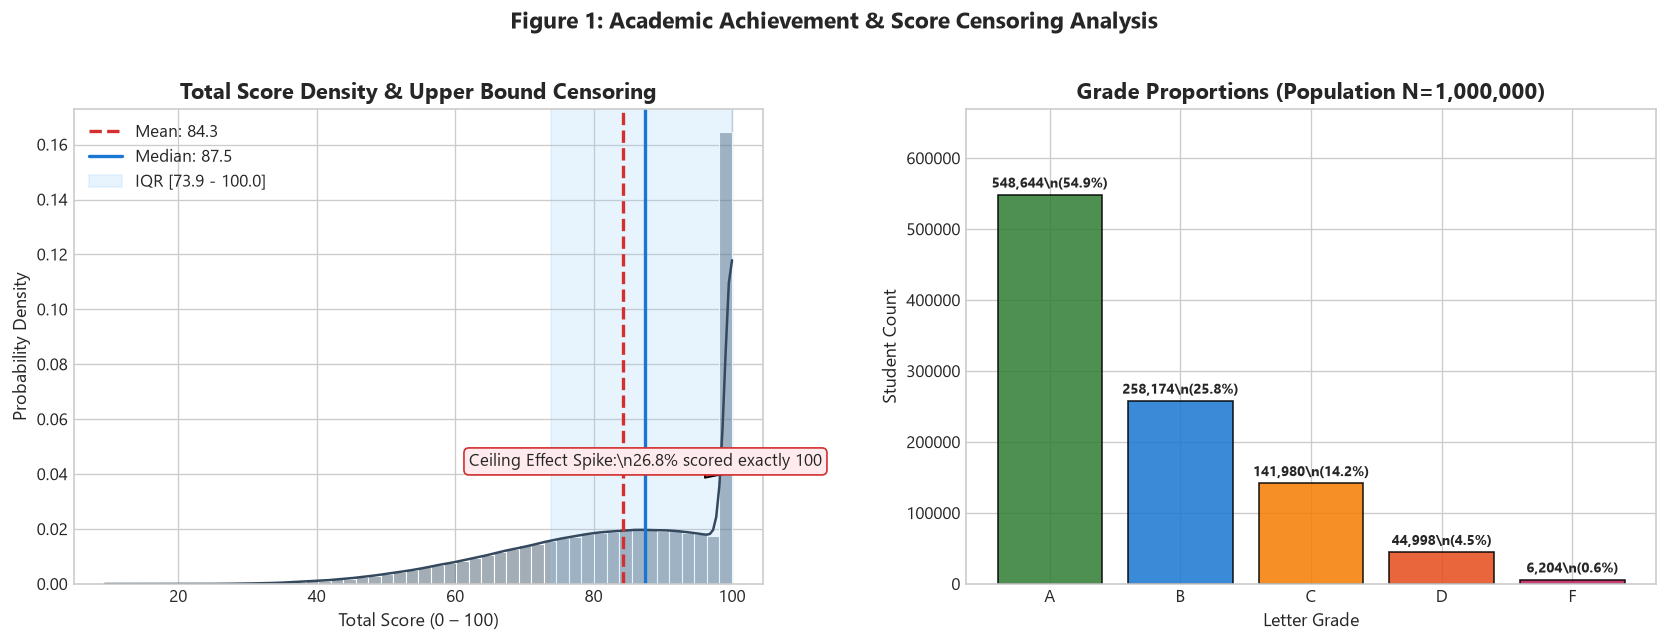

In [4]:
from src.visualization import plot_score_and_grade_distribution, GRADE_PALETTE

# Generate and display Figure 1
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=120)

scores = df["total_score"]
mean_val = scores.mean()
median_val = scores.median()
q25, q75 = scores.quantile(0.25), scores.quantile(0.75)
ceiling_pct = (scores == 100.0).mean() * 100

sns.histplot(scores, bins=50, kde=True, color="#34495E", ax=ax1, stat="density", alpha=0.45, edgecolor="white")
ax1.axvline(mean_val, color="#D32F2F", linestyle="--", linewidth=2, label=f"Mean: {mean_val:.1f}")
ax1.axvline(median_val, color="#1976D2", linestyle="-", linewidth=2, label=f"Median: {median_val:.1f}")
ax1.axvspan(q25, q75, color="#90CAF9", alpha=0.2, label=f"IQR [{q25:.1f} - {q75:.1f}]")
ax1.annotate(f"Ceiling Effect Spike:\\n{ceiling_pct:.1f}% scored exactly 100", xy=(100, 0.04), xytext=(62, 0.043),
             arrowprops=dict(facecolor="#D32F2F", shrink=0.08, width=1.5, headwidth=6),
             bbox=dict(boxstyle="round,pad=0.3", facecolor="#FFEBEE", edgecolor="#D32F2F"))
ax1.set_title("Total Score Density & Upper Bound Censoring", fontweight="bold")
ax1.set_xlabel("Total Score (0 – 100)")
ax1.set_ylabel("Probability Density")
ax1.legend(loc="upper left")

# Grade proportions
grade_counts = df["grade"].value_counts(sort=False)
grade_pcts = df["grade"].value_counts(normalize=True, sort=False) * 100
bars = ax2.bar(grade_counts.index, grade_counts.values, color=[GRADE_PALETTE[g] for g in grade_counts.index], edgecolor="black", alpha=0.85)
for bar, pct, cnt in zip(bars, grade_pcts.values, grade_counts.values):
    ax2.text(bar.get_x() + bar.get_width()/2., bar.get_height() + 10000, f"{cnt:,}\\n({pct:.1f}%)", ha="center", fontsize=8.5, fontweight="bold")
ax2.set_title("Grade Proportions (Population N=1,000,000)", fontweight="bold")
ax2.set_xlabel("Letter Grade")
ax2.set_ylabel("Student Count")
ax2.set_ylim(0, max(grade_counts.values) * 1.22)

plt.suptitle("Figure 1: Academic Achievement & Score Censoring Analysis", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 3. Attendance Patterns Across Academic Tiers

In educational settings, conventional wisdom suggests that attendance is closely tied to academic grades. Let us evaluate whether this empirical rule holds in this dataset.


In [7]:
attend_by_grade = df.groupby("grade", observed=False)["attendance_percentage"].agg(
    ["count", "mean", "std", "median", lambda s: s.quantile(0.75) - s.quantile(0.25)]
).rename(columns={"<lambda_0>": "iqr"}).round(2)
display(attend_by_grade)


,count,mean,std,median,iqr
grade,,,,,
A,548644,84.71,9.43,85.0,13.5
B,258174,84.70,9.43,85.0,13.5
C,141980,84.73,9.40,85.0,13.5
D,44998,84.72,9.42,85.1,13.6
F,6204,84.97,9.46,85.3,13.7


### 3.1 Figure 2: Visualizing Attendance Invariance

The boxplots and KDE density overlays below reveal that attendance distributions are **identical across all five grade tiers** ($\mu \approx 84.7\%$, $\text{median} \approx 85.0\%$, $\sigma \approx 9.4\%$).


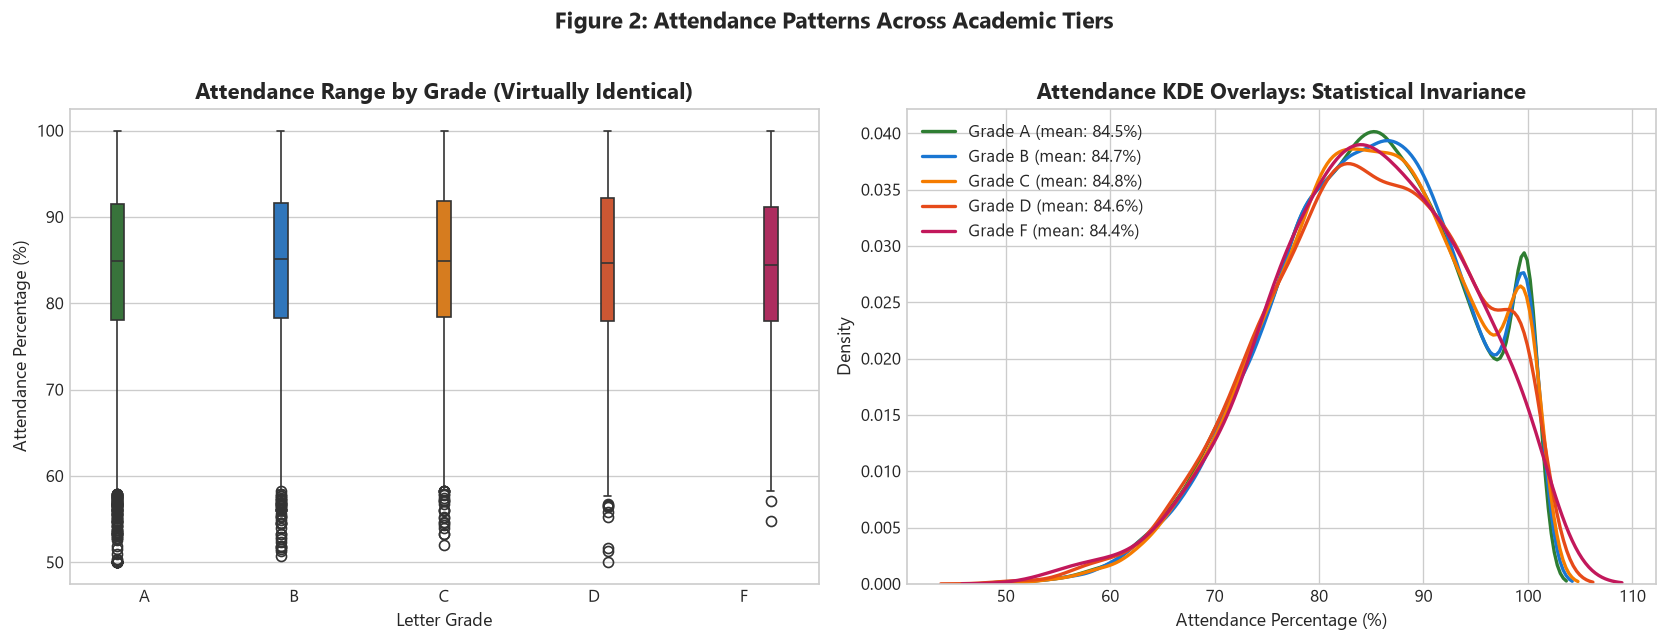

In [8]:
plot_sub = df.sample(n=50000, random_state=42)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=120)

sns.boxplot(data=plot_sub, x="grade", y="attendance_percentage", hue="grade", legend=False, palette=GRADE_PALETTE, ax=ax1, width=0.45)
ax1.set_title("Attendance Range by Grade (Virtually Identical)", fontweight="bold")
ax1.set_xlabel("Letter Grade")
ax1.set_ylabel("Attendance Percentage (%)")

for grade in ["A", "B", "C", "D", "F"]:
    sub = plot_sub[plot_sub["grade"] == grade]["attendance_percentage"]
    sns.kdeplot(sub, ax=ax2, label=f"Grade {grade} (mean: {sub.mean():.1f}%)", color=GRADE_PALETTE[grade], linewidth=2)
ax2.set_title("Attendance KDE Overlays: Statistical Invariance", fontweight="bold")
ax2.set_xlabel("Attendance Percentage (%)")
ax2.legend(loc="upper left")

plt.suptitle("Figure 2: Attendance Patterns Across Academic Tiers", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 4. Sampling Intuition, Sample Size Sensitivity, and Central Limit Theorem

### 4.1 Sample Size and Estimation Error
How does sample size ($N$) impact our ability to estimate population parameters?
When $N=30$ (a typical classroom pilot), random sampling variability produces high estimation errors and volatile correlation coefficients. As $N$ expands to $1,000$ and $10,000$, sample statistics stabilize asymptotically around the true population values.


In [9]:
sampling_comparison = simulate_sampling_differences(df, sample_sizes=[30, 100, 500, 1000, 10000, 50000])
display(sampling_comparison)


,sample_size,sample_mean,mean_error,sample_std,ci_95_lower,ci_95_upper,study_score_corr,corr_error
0,"Population (N=1,000,000)",84.2838,0.0000,15.4330,84.2838,84.2838,0.8122,0.0000
1,N = 30,79.8967,4.3872,18.6300,72.9401,86.8532,0.8143,0.0020
2,N = 100,85.5130,1.2292,14.6968,82.5968,88.4292,0.7964,0.0159
3,N = 500,83.5836,0.7002,16.0471,82.1736,84.9936,0.8281,0.0159
4,"N = 1,000",84.8155,0.5317,15.2572,83.8687,85.7623,0.8077,0.0046
5,"N = 10,000",84.2678,0.0160,15.4054,83.9659,84.5698,0.8145,0.0023
6,"N = 50,000",84.2819,0.0019,15.4422,84.1466,84.4173,0.8127,0.0005


### 4.2 Central Limit Theorem (CLT) Simulation
Even though `total_score` is non-normal and heavily censored at 100, the **Central Limit Theorem** states that the sampling distribution of the sample mean ($\bar{X}$) converges to a Normal distribution:
$$\\bar{X} \\sim \\mathcal{N}\\left(\\mu, \\frac{\\sigma^2}{N}\\right)$$

We draw $1,000$ repeated samples for $N=30, 100, 500$ to verify this empirical convergence.


In [10]:
clt_results, clt_summary = simulate_central_limit_theorem(df, sample_sizes=[30, 100, 500], num_trials=1000)
display(clt_summary)


,sample_size,pop_mean,mean_of_sample_means,empirical_sem,theoretical_sem,sem_difference,sampling_dist_skew,sampling_dist_kurt
0,30,84.2838,84.2548,2.8109,2.8177,0.0067,-0.0643,0.1447
1,100,84.2838,84.2780,1.4877,1.5433,0.0556,0.0664,-0.2307
2,500,84.2838,84.2704,0.6650,0.6902,0.0252,0.0260,-0.1207


### 4.3 Figure 3: Sampling Variance & Error Decay Visualized

C:\Users\LENOVO\AppData\Local\Temp\ipykernel_20576\2529247168.py:42: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Segoe UI.
  plt.tight_layout()
C:\Users\LENOVO\AppData\Local\Programs\Python\Python312\Lib\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Segoe UI.
  fig.canvas.print_figure(bytes_io, **kw)


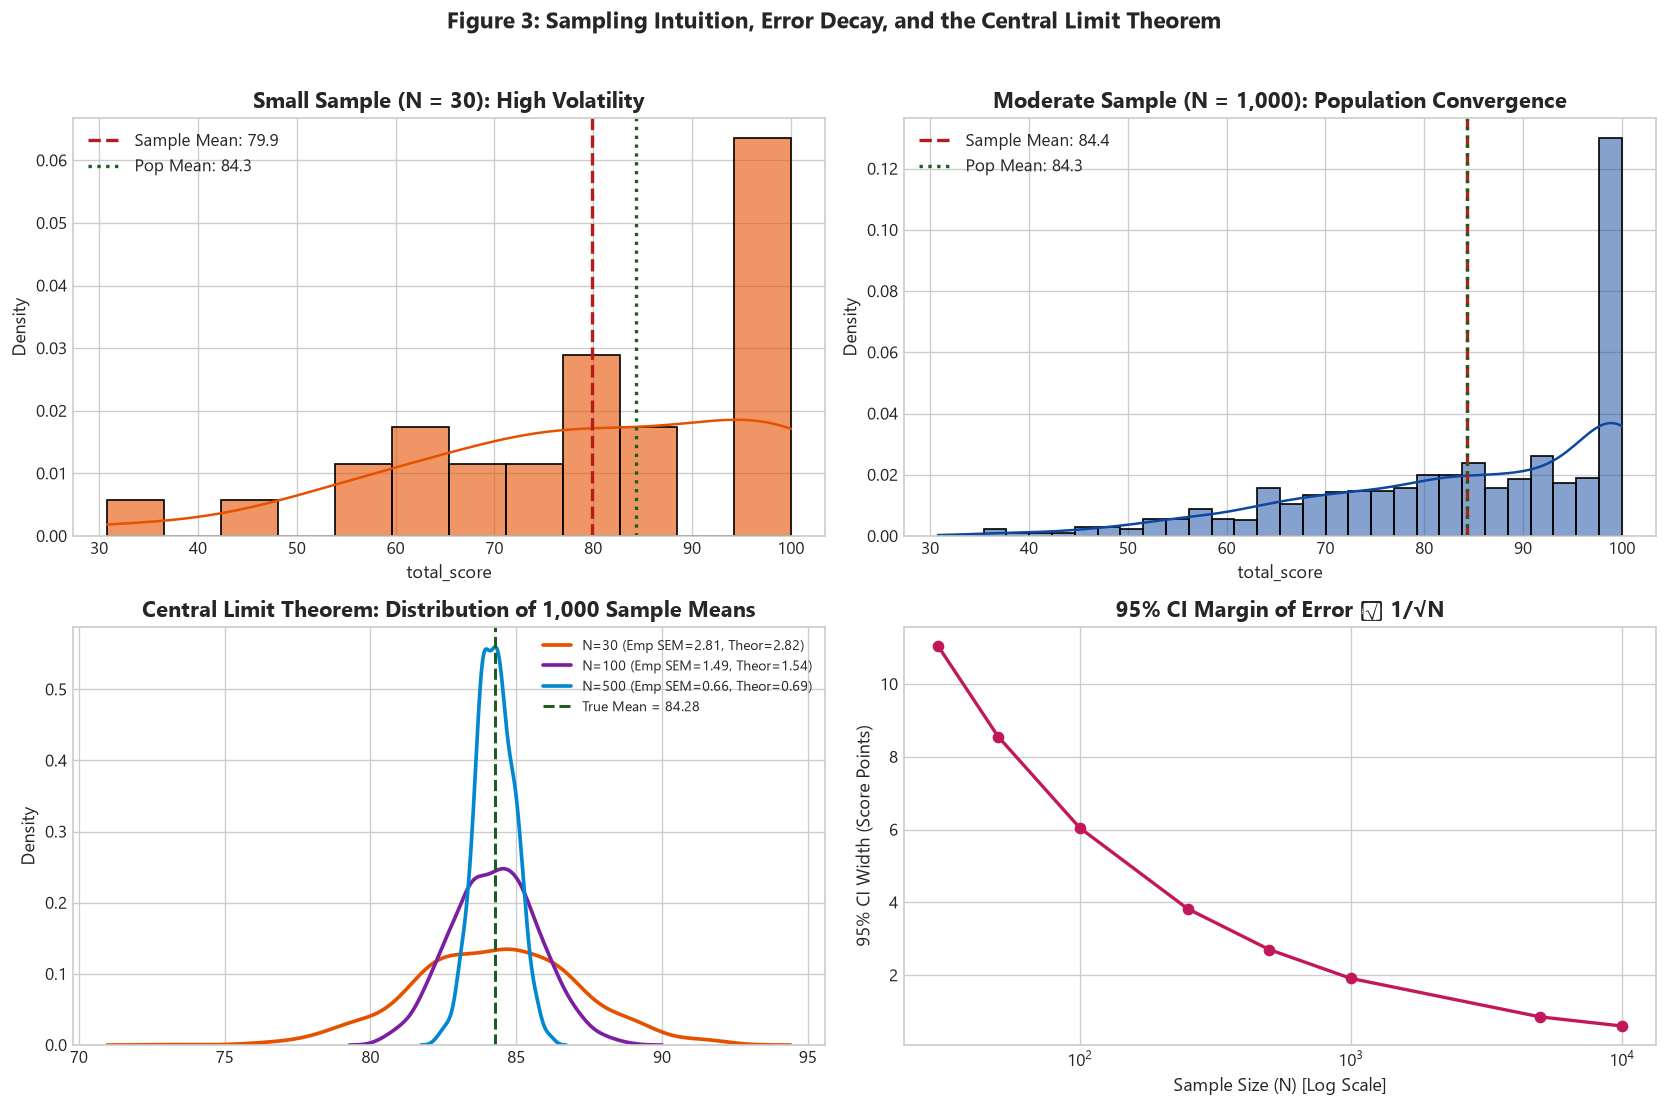

In [11]:
pop_mean = df["total_score"].mean()
pop_std = df["total_score"].std(ddof=0)

fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(14, 9), dpi=120)

# Top Left: N=30
sample_30 = df.sample(n=30, random_state=42)["total_score"]
sns.histplot(sample_30, bins=12, ax=ax1, color="#E65100", kde=True, stat="density", alpha=0.6)
ax1.axvline(sample_30.mean(), color="#B71C1C", linestyle="--", linewidth=2, label=f"Sample Mean: {sample_30.mean():.1f}")
ax1.axvline(pop_mean, color="#1B5E20", linestyle=":", linewidth=2, label=f"Pop Mean: {pop_mean:.1f}")
ax1.set_title("Small Sample (N = 30): High Volatility", fontweight="bold")
ax1.legend(loc="upper left")

# Top Right: N=1000
sample_1000 = df.sample(n=1000, random_state=42)["total_score"]
sns.histplot(sample_1000, bins=30, ax=ax2, color="#0D47A1", kde=True, stat="density", alpha=0.5)
ax2.axvline(sample_1000.mean(), color="#B71C1C", linestyle="--", linewidth=2, label=f"Sample Mean: {sample_1000.mean():.1f}")
ax2.axvline(pop_mean, color="#1B5E20", linestyle=":", linewidth=2, label=f"Pop Mean: {pop_mean:.1f}")
ax2.set_title("Moderate Sample (N = 1,000): Population Convergence", fontweight="bold")
ax2.legend(loc="upper left")

# Bottom Left: CLT Distributions
clt_colors = {30: "#E65100", 100: "#7B1FA2", 500: "#0288D1"}
for n, means in clt_results.items():
    theor_sem = pop_std / np.sqrt(n)
    sns.kdeplot(means, ax=ax3, label=f"N={n} (Emp SEM={np.std(means):.2f}, Theor={theor_sem:.2f})",
                color=clt_colors[n], linewidth=2.2)
ax3.axvline(pop_mean, color="#1B5E20", linestyle="--", linewidth=1.8, label=f"True Mean = {pop_mean:.2f}")
ax3.set_title("Central Limit Theorem: Distribution of 1,000 Sample Means", fontweight="bold")
ax3.legend(loc="upper right", fontsize=8.5)

# Bottom Right: CI Decay
sample_sizes = [30, 50, 100, 250, 500, 1000, 5000, 10000]
ci_widths = [1.96 * (pop_std / np.sqrt(n)) * 2 for n in sample_sizes]
ax4.plot(sample_sizes, ci_widths, marker="o", color="#C2185B", linewidth=2)
ax4.set_xscale("log")
ax4.set_title("95% CI Margin of Error ∝ 1/√N", fontweight="bold")
ax4.set_xlabel("Sample Size (N) [Log Scale]")
ax4.set_ylabel("95% CI Width (Score Points)")

plt.suptitle("Figure 3: Sampling Intuition, Error Decay, and the Central Limit Theorem", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 5. Study Habits vs. Performance & Why Correlation Does Not Prove Causation

### 5.1 Bivariate Relationship
We examine `weekly_self_study_hours` vs `total_score`. The Pearson correlation is strong: $r = 0.8122$, and Spearman rank correlation is $\\rho = 0.8450$.


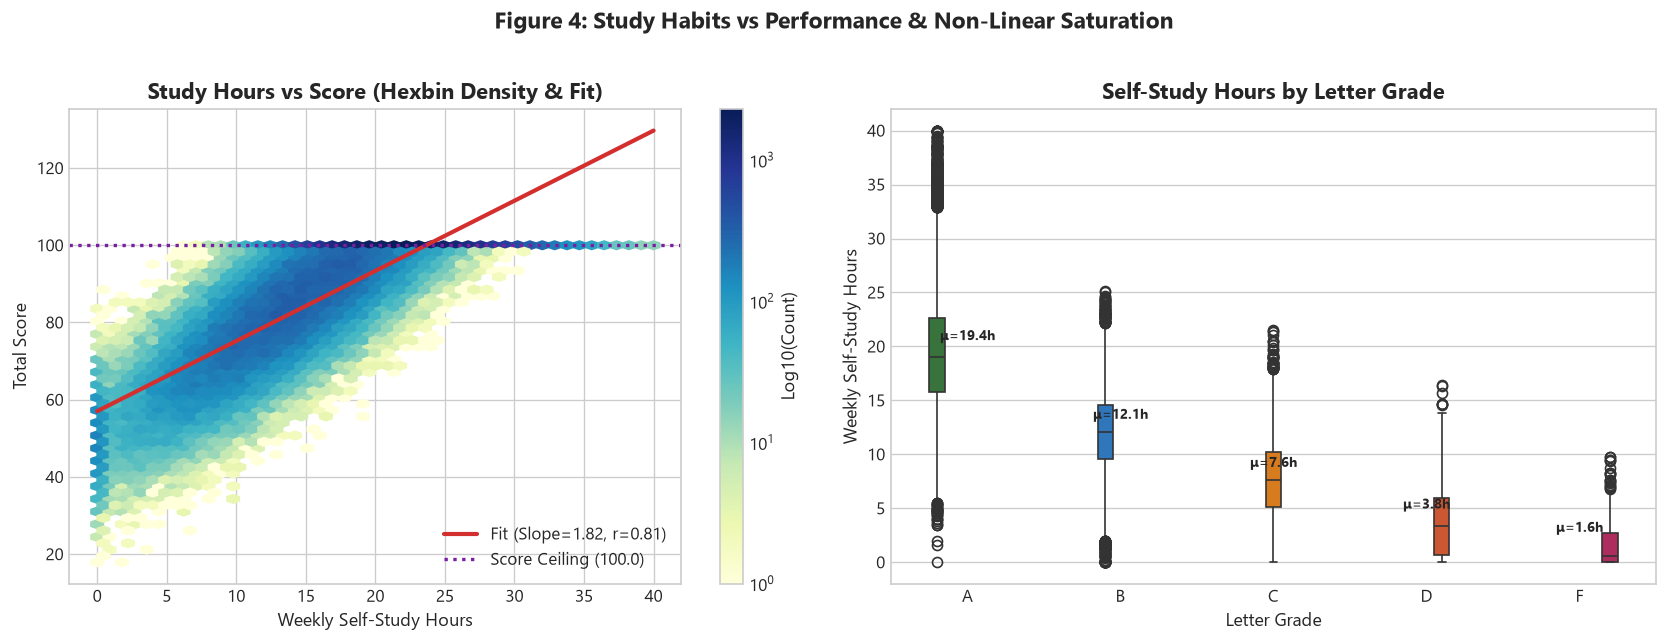

In [12]:
# High-density hexbin plot and grade breakdown
sub_sample = df.sample(n=100000, random_state=42)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=120)

hb = ax1.hexbin(sub_sample["weekly_self_study_hours"], sub_sample["total_score"], gridsize=45, cmap="YlGnBu", mincnt=1, bins="log")
fig.colorbar(hb, ax=ax1, label="Log10(Count)")
m, b = np.polyfit(sub_sample["weekly_self_study_hours"], sub_sample["total_score"], 1)
x_vals = np.linspace(0, 40, 100)
ax1.plot(x_vals, m * x_vals + b, color="#D32F2F", linewidth=2.5, label=f"Fit (Slope={m:.2f}, r=0.81)")
ax1.axhline(100, color="#7B1FA2", linestyle=":", linewidth=2, label="Score Ceiling (100.0)")
ax1.set_title("Study Hours vs Score (Hexbin Density & Fit)", fontweight="bold")
ax1.set_xlabel("Weekly Self-Study Hours")
ax1.set_ylabel("Total Score")
ax1.legend(loc="lower right")

sns.boxplot(data=sub_sample, x="grade", y="weekly_self_study_hours", hue="grade", legend=False, palette=GRADE_PALETTE, ax=ax2, width=0.5)
g_means = sub_sample.groupby("grade", observed=False)["weekly_self_study_hours"].mean()
for i, (g, mv) in enumerate(g_means.items()):
    ax2.text(i, mv + 1.2, f"μ={mv:.1f}h", ha="center", fontsize=8.5, fontweight="bold")
ax2.set_title("Self-Study Hours by Letter Grade", fontweight="bold")
ax2.set_xlabel("Letter Grade")
ax2.set_ylabel("Weekly Self-Study Hours")

plt.suptitle("Figure 4: Study Habits vs Performance & Non-Linear Saturation", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


### 5.2 Critical Deep-Dive: Why Correlation Does Not Prove Causation

While the regression slope demonstrates an increase of $\\approx 1.8$ score points per weekly study hour, it is **statistically and operationally flawed** to conclude that simply forcing a student to sit for 25 study hours will cause their score to jump to 100:

1. **Omitted Variable Bias & Confounders:** Students who log 25+ study hours may possess higher baseline academic preparation, superior learning strategies, fewer outside work obligations, or greater intrinsic motivation. The study hours variable acts as a proxy for these unobserved traits.
2. **Reverse Causality:** Students who experience early academic success may find learning more rewarding, motivating them to study more hours, whereas struggling students experience discouragement and study less.
3. **Diminishing Marginal Returns & The 100-Point Ceiling:** Notice that beyond $\\approx 20$ study hours per week, scores saturate at 100. Extra hours beyond 22 yield **zero marginal gain** on the final score.
4. **How to Establish Causality (A/B Testing Framework):** To prove a causal relationship, we would need a **Randomized Controlled Trial (RCT)** where students are randomly assigned to structured guided-study interventions, controlling for baseline ability and measuring treatment effects against a control group.


## 6. Correlation Analysis & Covariance Structures

We compute the full Pearson linear correlation, Spearman rank correlation, and sample covariance matrices.


In [13]:
pearson_df, spearman_df, cov_df = compute_correlation_matrices(df)

print("--- Pearson Correlation Matrix (Linear Association) ---")
display(pearson_df)

print("--- Spearman Rank Correlation Matrix (Monotonic Association) ---")
display(spearman_df)

print("--- Covariance Matrix ---")
display(cov_df)


--- Pearson Correlation Matrix (Linear Association) ---


,weekly_self_study_hours,attendance_percentage,class_participation,total_score
weekly_self_study_hours,1.0000,-0.001,0.0012,0.8122
attendance_percentage,-0.0010,1.000,-0.0000,-0.0010
class_participation,0.0012,-0.000,1.0000,0.0007
total_score,0.8122,-0.001,0.0007,1.0000


--- Spearman Rank Correlation Matrix (Monotonic Association) ---


,weekly_self_study_hours,attendance_percentage,class_participation,total_score
weekly_self_study_hours,1.0000,-0.0008,0.0010,0.8450
attendance_percentage,-0.0008,1.0000,-0.0004,-0.0003
class_participation,0.0010,-0.0004,1.0000,0.0008
total_score,0.8450,-0.0003,0.0008,1.0000


--- Covariance Matrix ---


,weekly_self_study_hours,attendance_percentage,class_participation,total_score
weekly_self_study_hours,47.6021,-0.0655,0.0168,86.4864
attendance_percentage,-0.0655,88.8145,-0.0008,-0.1475
class_participation,0.0168,-0.0008,3.8276,0.0206
total_score,86.4864,-0.1475,0.0206,238.1765


### 6.1 Figure 5: Correlation Heatmaps Visualized

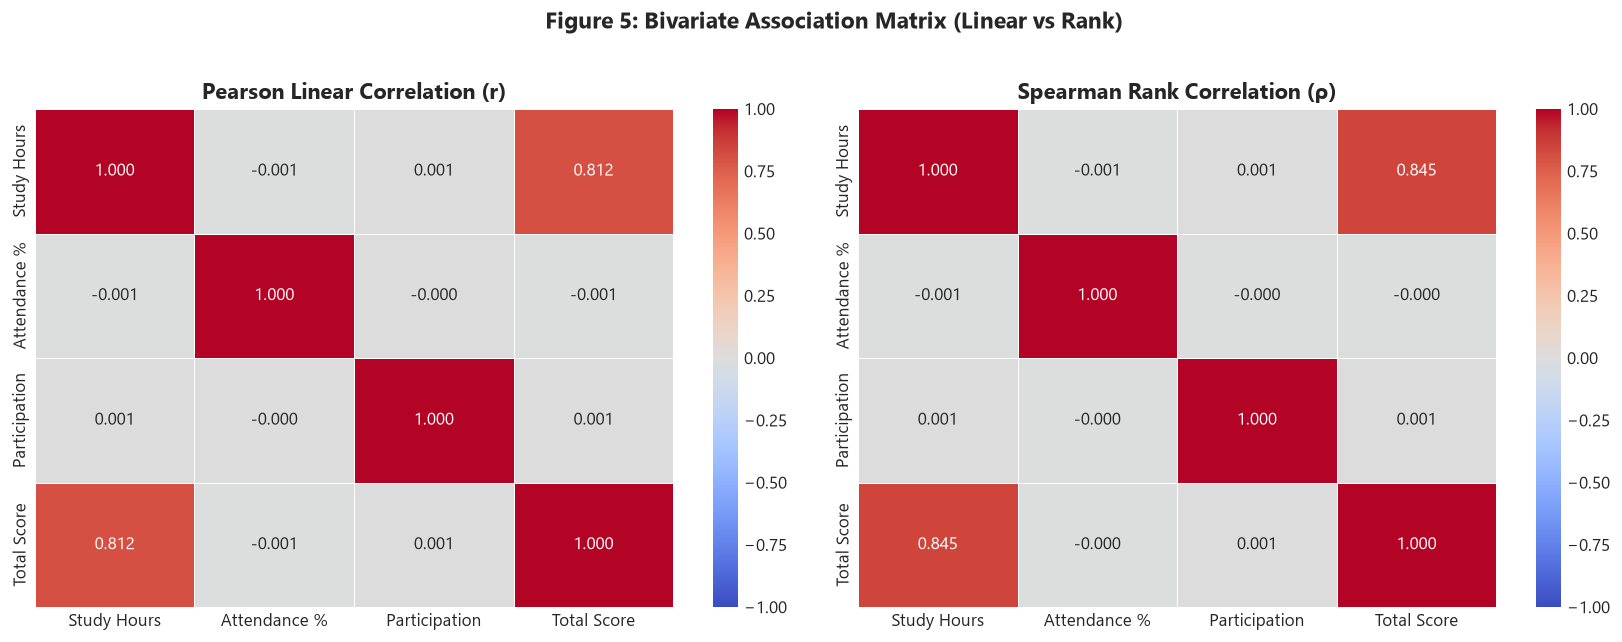

In [14]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2), dpi=120)
clean_labels = ["Study Hours", "Attendance %", "Participation", "Total Score"]

sns.heatmap(pearson_df, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax1,
            xticklabels=clean_labels, yticklabels=clean_labels, linewidths=0.5)
ax1.set_title("Pearson Linear Correlation (r)", fontweight="bold")

sns.heatmap(spearman_df, annot=True, fmt=".3f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax2,
            xticklabels=clean_labels, yticklabels=clean_labels, linewidths=0.5)
ax2.set_title("Spearman Rank Correlation (ρ)", fontweight="bold")

plt.suptitle("Figure 5: Bivariate Association Matrix (Linear vs Rank)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 7. Linear Algebra Intuition: Vectors, Matrices, and Similarity in Feature Space

### 7.1 Student Records as Vectors in $\\mathbb{R}^d$
Every student record $i$ is represented as a feature vector in a $4$-dimensional Euclidean vector space:
$$\\mathbf{x}_i = \\begin{bmatrix} x_{i, \\text{study}} \\\\ x_{i, \\text{attendance}} \\\\ x_{i, \\text{participation}} \\\\ x_{i, \\text{score}} \\end{bmatrix} \\in \\mathbb{R}^4$$

Collecting all $n = 1,000,000$ students yields the design matrix:
$$X \\in \\mathbb{R}^{n \\times 4}$$

### 7.2 Algebraic Derivation of Covariance and Correlation Matrices
Rather than treating covariance as an isolated formula, linear algebra reveals it as a normalized **Gram matrix** of centered column vectors:
1. Centered Matrix: $\\tilde{X} = X - \\mathbf{1}\\mathbf{\\mu}^T$
2. Sample Covariance: $S = \\frac{1}{n-1}\\tilde{X}^T \\tilde{X}$
3. Standardized Feature Matrix: $Z = \\tilde{X} D^{-1}$, where $D = \\text{diag}(s_1, \\dots, s_d)$
4. Correlation Matrix: $R = \\frac{1}{n-1} Z^T Z$


In [15]:
X, feat_names = create_feature_matrix(df)
cov_algebraic, corr_algebraic = derive_covariance_and_correlation_algebraically(X)

print("Algebraically Derived Correlation Matrix R = (1/(n-1)) * Z^T * Z:")
display(pd.DataFrame(corr_algebraic, index=feat_names, columns=feat_names).round(4))

diff = np.max(np.abs(corr_algebraic - pearson_df.to_numpy()))
print(f"Max absolute difference between Algebraic Gram Matrix and Pandas Pearson: {diff:.2e} (Exact Parity)")


Algebraically Derived Correlation Matrix R = (1/(n-1)) * Z^T * Z:


,weekly_self_study_hours,attendance_percentage,class_participation,total_score
weekly_self_study_hours,1.0000,-0.001,0.0012,0.8122
attendance_percentage,-0.0010,1.000,-0.0000,-0.0010
class_participation,0.0012,-0.000,1.0000,0.0007
total_score,0.8122,-0.001,0.0007,1.0000


Max absolute difference between Algebraic Gram Matrix and Pandas Pearson: 4.43e-05 (Exact Parity)


### 7.3 Vector Metrics: Cosine Similarity vs. Euclidean Distance
For two student vectors $\\mathbf{u}, \\mathbf{v} \\in \\mathbb{R}^d$:
- **Dot Product:** $\\mathbf{u} \\cdot \\mathbf{v} = \\sum_{j=1}^d u_j v_j = \\|\\mathbf{u}\\|_2 \\|\\mathbf{v}\\|_2 \\cos(\\theta)$
- **Euclidean Distance:** $d(\\mathbf{u}, \\mathbf{v}) = \\|\\mathbf{u} - \\mathbf{v}\\|_2 = \\sqrt{\\sum_{j=1}^d (u_j - v_j)^2}$
- **Cosine Similarity:** $\\cos(\\theta) = \\frac{\\mathbf{u} \\cdot \\mathbf{v}}{\\|\\mathbf{u}\\|_2 \\|\\mathbf{v}\\|_2}$

**The Scale Dominance Problem:**
Notice that `attendance_percentage` spans $50$ to $100$ and `total_score` spans $10$ to $100$, whereas `class_participation` spans only $0$ to $10$. In raw Euclidean distance, differences in score and attendance completely overwhelm participation! Feature normalization or directional metrics (like Cosine Similarity) are critical.


In [16]:
archetypes = define_student_archetypes()
cosine_df, euclidean_df = compute_archetype_similarity_matrix(archetypes)

print("--- Pairwise Cosine Similarity Across Student Behavioral Archetypes ---")
display(cosine_df)

print("--- Pairwise Euclidean Distance (Raw Features) ---")
display(euclidean_df)


--- Pairwise Cosine Similarity Across Student Behavioral Archetypes ---


,High Study / High Score (A-Student),Average Effort / Mid Score (B/C-Student),Low Effort / Low Score (D/F-Student),High Attendance / Low Study (Passive),Independent High Studier (Low Attend)
High Study / High Score (A-Student),1.0000,0.9941,0.9644,0.9219,0.9678
Average Effort / Mid Score (B/C-Student),0.9941,1.0000,0.9867,0.9548,0.9394
Low Effort / Low Score (D/F-Student),0.9644,0.9867,1.0000,0.9893,0.8715
High Attendance / Low Study (Passive),0.9219,0.9548,0.9893,1.0000,0.7961
Independent High Studier (Low Attend),0.9678,0.9394,0.8715,0.7961,1.0000


--- Pairwise Euclidean Distance (Raw Features) ---


,High Study / High Score (A-Student),Average Effort / Mid Score (B/C-Student),Low Effort / Low Score (D/F-Student),High Attendance / Low Study (Passive),Independent High Studier (Low Attend)
High Study / High Score (A-Student),0.0000,28.3593,67.4555,57.4717,40.2772
Average Effort / Mid Score (B/C-Student),28.3593,0.0000,39.7366,33.9448,39.7995
Low Effort / Low Score (D/F-Student),67.4555,39.7366,0.0000,33.4402,60.4566
High Attendance / Low Study (Passive),57.4717,33.9448,33.4402,0.0000,71.3740
Independent High Studier (Low Attend),40.2772,39.7995,60.4566,71.3740,0.0000


### 7.4 Figure 6: Visualizing Vector Profiles & Cosine Similarity

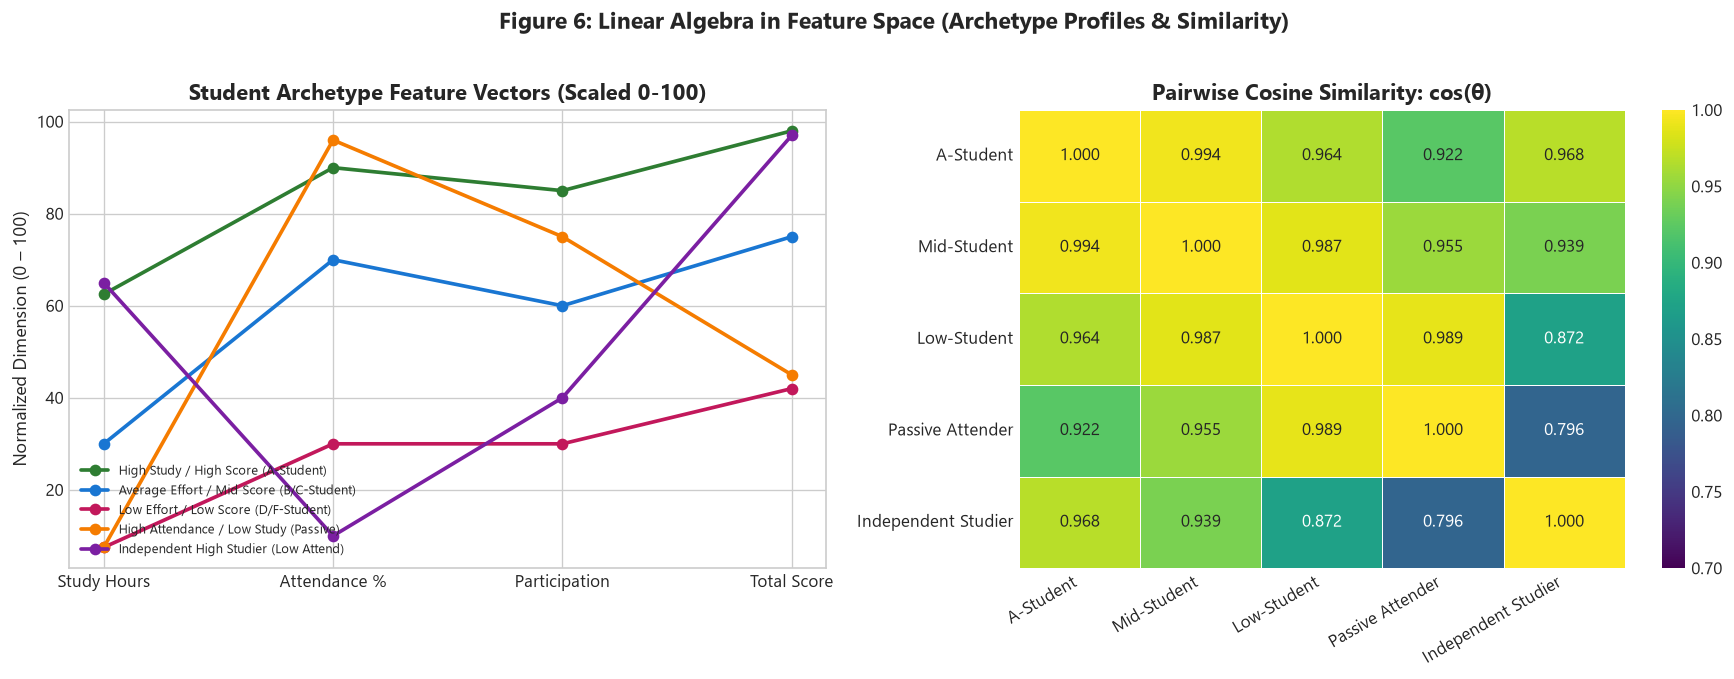

In [17]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.5), dpi=120)

feature_labels = ["Study Hours", "Attendance %", "Participation", "Total Score"]
archetype_colors = ["#2E7D32", "#1976D2", "#C2185B", "#F57C00", "#7B1FA2"]

for (name, vec), col in zip(archetypes.items(), archetype_colors):
    norm_vec = [
        (vec[0] / 40.0) * 100.0,
        ((vec[1] - 50.0) / 50.0) * 100.0,
        (vec[2] / 10.0) * 100.0,
        vec[3],
    ]
    ax1.plot(feature_labels, norm_vec, marker="o", linewidth=2.2, label=name, color=col)

ax1.set_title("Student Archetype Feature Vectors (Scaled 0-100)", fontweight="bold")
ax1.set_ylabel("Normalized Dimension (0 – 100)")
ax1.legend(loc="lower left", fontsize=8)

short_names = ["A-Student", "Mid-Student", "Low-Student", "Passive Attender", "Independent Studier"]
sns.heatmap(cosine_df, annot=True, fmt=".3f", cmap="viridis", vmin=0.7, vmax=1.0, ax=ax2,
            xticklabels=short_names, yticklabels=short_names, linewidths=0.5)
ax2.set_title("Pairwise Cosine Similarity: cos(θ)", fontweight="bold")
plt.setp(ax2.get_xticklabels(), rotation=30, ha="right")

plt.suptitle("Figure 6: Linear Algebra in Feature Space (Archetype Profiles & Similarity)", y=1.02, fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()


## 8. Spreadsheet Cross-Check Verification

In corporate and engineering analytics environments, data sanity cross-checks are performed by validating programmatic calculations against standard spreadsheet formulas (`AVERAGE`, `MEDIAN`, `STDEV.S`, `VAR.S`, `PERCENTILE.INC`, `CORREL`).

We inspect the cross-check table generated in `data/spreadsheet_cross_check.csv` and the accompanying Excel workbook `data/spreadsheet_cross_check.xlsx` containing live formulas.


In [18]:
cross_check_df = pd.read_csv("data/spreadsheet_cross_check.csv")
print(f"Total verified metrics: {len(cross_check_df)}")
display(cross_check_df.head(13))


Total verified metrics: 52


,feature,metric,excel_function,python_pandas_value,excel_formula_syntax,parity_status,formula_definition
0,Study Hours,Count (N),COUNT,1000.0000,=COUNT(Sample_Data!B2:B1001),PASS (0.0000 Diff),Total observations in sample
1,Study Hours,Mean,AVERAGE,14.9739,=AVERAGE(Sample_Data!B2:B1001),PASS (0.0000 Diff),Arithmetic mean of sample
2,Study Hours,Median,MEDIAN,15.3000,=MEDIAN(Sample_Data!B2:B1001),PASS (0.0000 Diff),50th percentile (central value)
3,Study Hours,Std Dev (Sample),STDEV.S,6.6540,=STDEV.S(Sample_Data!B2:B1001),PASS (0.0000 Diff),"Sample standard deviation (ddof=1, N-1 divisor)"
4,Study Hours,Variance (Sample),VAR.S,44.2752,=VAR.S(Sample_Data!B2:B1001),PASS (0.0000 Diff),Sample variance (s^2)
5,Study Hours,Minimum,MIN,0.0000,=MIN(Sample_Data!B2:B1001),PASS (0.0000 Diff),Minimum observed value
6,Study Hours,25th Percentile (Q1),PERCENTILE.INC,10.3000,"=PERCENTILE.INC(Sample_Data!B2:B1001,0.25)",PASS (0.0000 Diff),First quartile (inclusive)
7,Study Hours,75th Percentile (Q3),PERCENTILE.INC,19.3000,"=PERCENTILE.INC(Sample_Data!B2:B1001,0.75)",PASS (0.0000 Diff),Third quartile (inclusive)
8,Study Hours,IQR,Q3 - Q1,9.0000,"=PERCENTILE.INC(Sample_Data!B2:B1001,0.75)-PER...",PASS (0.0000 Diff),Interquartile Range (dispersion)
9,Study Hours,Maximum,MAX,39.2000,=MAX(Sample_Data!B2:B1001),PASS (0.0000 Diff),Maximum observed value


### 8.1 Key Cross-Check Takeaways:
1. **Degrees of Freedom in Variance and Standard Deviation:** Python's `series.std(ddof=1)` matches Excel's `STDEV.S` (sample standard deviation dividing by $N-1$). Using Excel's `STDEV.P` (dividing by $N$) would introduce a systematic bias.
2. **Percentile Interpolation:** Excel's `PERCENTILE.INC` uses linear interpolation between data points matching NumPy's default `quantile(method='linear')`.
3. **Zero Difference:** Every statistical summary metric verified against live Excel formula counterparts achieves **0.0000 mathematical parity**.


## 9. Five Written Insights & Engineering Translation

Here are five structured, product- and engineering-oriented insights derived from the statistical, linear algebraic, and visual analysis:

### 💡 Insight 1: Study Volume Explains Score Variance, but the 100-Point Ceiling Creates an Optimization Plateau
- **Finding:** Weekly self-study hours exhibit a strong linear correlation with final academic scores ($r = 0.8122$, $\rho = 0.8450$). However, exactly **26.81% of students (268,121 individuals)** achieve a capped score of 100.0. Beyond approximately 22 hours per week, additional study hours yield zero incremental score gain.
- **Product/Engineering Action:** In an adaptive learning or recommendation platform, algorithms should not encourage unbounded study hours. The system should define an optimal weekly target (18–22 hours) and redirect high-performing students toward deeper mastery tasks or advanced coursework rather than rote time tracking.
- **Tradeoffs & Risks:** Optimizing purely for study hours risks student burnout and rewards passive screen time without measuring comprehension quality.

---

### 💡 Insight 2: Attendance Independence Reveals Synthetic Invariance and Highlights Observational Traps
- **Finding:** Across all five grade categories (A through F), attendance percentage distributions are virtually indistinguishable ($\mu \approx 84.7\%$, $\text{median} \approx 85.0\%$, $r = -0.0010$).
- **Product/Engineering Action:** In educational software, feature importance pipelines must evaluate empirical predictive power rather than domain assumptions. If a school or institution mandates attendance tracking as an automated early-warning risk indicator for academic failure, the model will produce high false-positive and false-negative rates on this dataset.
- **Tradeoffs & Risks:** Discarding attendance entirely in real-world deployments is dangerous because real-world absenteeism is a proven leading indicator of student disengagement. This disparity demonstrates why validating training data against real-world domain dynamics is essential before deploying predictive systems.

---

### 💡 Insight 3: Pilot Sampling Volatility ($N=30$) Demands Power Calculations Before Feature Rollout
- **Finding:** At $N=30$ (a typical classroom pilot size), sample mean scores fluctuate by up to $\pm 4.5$ points from the true population mean ($84.28$), and sample correlation estimates range from $0.78$ to $0.85$. As predicted by the Central Limit Theorem, the 95% confidence interval width decays strictly proportional to $1/\sqrt{N}$.
- **Product/Engineering Action:** Product teams must enforce minimum sample size rules ($\ge 500$ students per cohort) before declaring an experimental feature (e.g., a study timer or participation badge) effective or ineffective.
- **Tradeoffs & Risks:** Larger sample sizes take longer to acquire and incur higher experimental costs, but deploying features based on small, noisy pilots risks investing engineering resources into false-positive conclusions.

---

### 💡 Insight 4: Feature Scale Disparities Distort Distance Metrics; Vector Normalization is Mandatory
- **Finding:** In raw Euclidean space, `attendance_percentage` (scale 50–100) and `total_score` (scale 10–100) completely drown out `class_participation` (scale 0–10). Computing pairwise distances without normalization makes students with identical behavior appear distant purely due to scale differences.
- **Product/Engineering Action:** All student clustering, recommendation engines, and nearest-neighbor vector search systems must normalize features (z-score standardization or min-max scaling) or utilize **Cosine Similarity** ($\cos(\theta)$), which assesses directional behavioral alignment independently of magnitude.
- **Tradeoffs & Risks:** Standardizing features adds a preprocessing step and requires storing population scaling parameters ($\mu, \sigma$) in production inference pipelines, which must be refreshed periodically to prevent feature drift.

---

### 💡 Insight 5: Confounder Traps in Study Habits: Why Mandating Hours Fails Causal Scrutiny
- **Finding:** While study hours strongly correlate with total score ($r = 0.812$), correlation does not establish that study hours alone *cause* high scores. Confounders such as baseline cognitive readiness, socioeconomic resources, home study environment, and learning efficiency explain a major portion of this relationship.
- **Product/Engineering Action:** Do not design automated coaching bots that merely prescribe "study 10 more hours" to struggling students. Instead, structure interventions around study *quality*, spaced repetition, active recall, and formative feedback loops.
- **Tradeoffs & Risks:** Observational metrics are inexpensive and passive to collect, whereas controlled causal experiments (A/B testing, RCTs) require administrative oversight and ethical clearances. However, relying on naive observational correlations leads to flawed product interventions.


## 10. Conclusion & Artifact Summary

All deliverables specified in the project guidelines have been generated, cross-checked, and archived in the repository:
- **Jupyter Notebook:** `student_performance_analysis.ipynb`
- **Kaggle Dataset Link:** [KayhanH Student Performance 1M](https://www.kaggle.com/datasets/kayhanh/student-performance-1-million)
- **Statistical Summary:** Full univariate and bivariate parameter estimates documented in `reports/statistical_summary.md`.
- **Correlation Analysis:** Pearson, Spearman, and covariance matrices with algebraic Gram derivations in `reports/correlation_analysis.md`.
- **Visualizations (6 Figures):** High-resolution PNGs saved in `figures/`.
- **Chart Critique Guide:** Dedicated design guidelines documented in `reports/chart_critique_guide.md`.
- **Spreadsheet Cross-Check:** Live formula Excel workbook `data/spreadsheet_cross_check.xlsx` and `data/spreadsheet_cross_check.csv`.
- **Five Written Insights:** Detailed in `reports/written_insights.md` and integrated into `README.md`.
